# Corso di Probabilità e Statistica - La distribuzione binomiale

In questo capitolo introduciamo la distribuzione binomiale


In [240]:
import scipy.stats as stats #modulo di statistica
import numpy as np
import matplotlib.pyplot as plt

**Generiamo un processo binomiale empiricamente**

In [241]:
#parametri
n=10  #numero di tentativi
p=0.5 #probabilità di successo
NR=1000 #numero di realizzazioni del processo

In [242]:
bd = np.zeros(n+1) #inizializzazione

In [243]:
for i in range(NR): #loop sulle realizzazioni
    k=0 #k numero di successi
    for j in range(n): #loop su n
        x=np.random.rand() 
        if(x<p): #successo con probabilità p 
            k=k+1 
    bd[k]=bd[k]+1 

In [244]:
bd=bd/NR #normalizzazione

**Confrontiamo il risultato empirico con la distribuzione binomiale teorica**

In [245]:
bd1 = stats.binom(n, p) #distribuzione binomiale

In [246]:
# confrontiamo i valori di B_p^n(k)
k=3
bd[k],bd1.pmf(k)

(np.float64(0.128), np.float64(0.1171875))

In [247]:
# confrontiamo le media
mu1=bd1.mean()
mu=np.average(np.arange(n+1),weights=bd) #media pesata sulla distribuzione empirica 
mu,mu1

(np.float64(4.967000000000001), np.float64(5.0))

In [248]:
# confrontiamo la varianza
sigma2_1=bd1.var()
sigma2=np.average(np.arange(n+1)**2,weights=bd)-mu**2
sigma2,sigma2_1

(np.float64(2.557910999999983), np.float64(2.5))

In [249]:
# calcoliamo i momenti
r=3
mom1=bd1.moment(r)
mom=np.average(np.arange(n+1)**r,weights=bd)
mom1,mom

(np.float64(162.5), np.float64(160.679))

**Grafici**

In [250]:
# usiamo caratteri leggibili!
plt.rcParams.update({'font.size': 18})

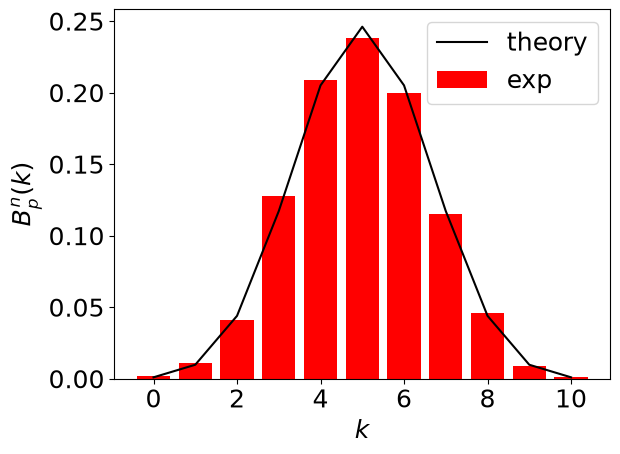

In [251]:
k = np.arange(n+1)
plt.plot(k, bd1.pmf(k), label="theory", color="black") #linee
plt.bar(k,bd, color='red', label="exp")
plt.xlabel(r'$k$') 
plt.ylabel(r'$B_p^n(k)$') #Se vogliamo usare il LaTex nel grafico r'$math$'
plt.legend()

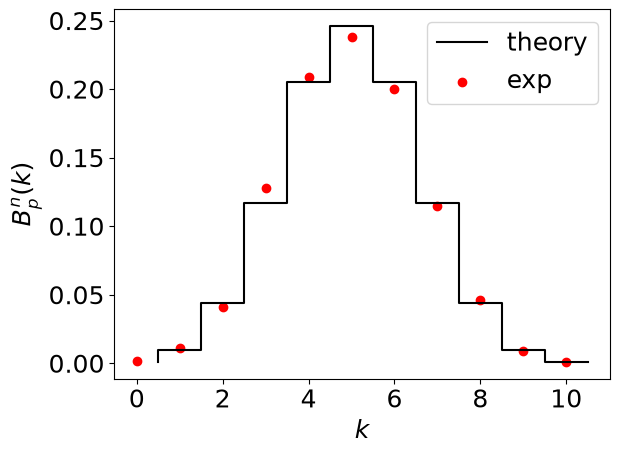

In [252]:
k = np.arange(n+1)
plt.step(k+.5, bd1.pmf(k), label="theory", color='black') #step
plt.scatter(k,bd, color='red', label="exp")
plt.xlabel(r'$k$') 
plt.ylabel(r'$B_p^n(k)$') #Se vogliamo usare il LaTex nel grafico r'$math$'
plt.legend()

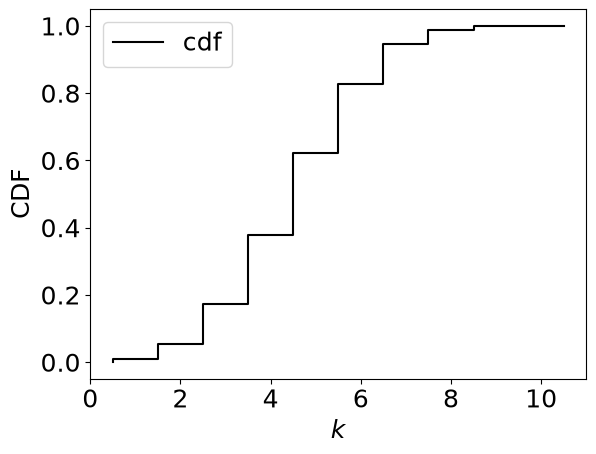

In [253]:
#distribuzione cumulata
plt.step(k+.5, bd1.cdf(k), label="cdf", color='black') #step
plt.xlabel(r'$k$') 
plt.ylabel('CDF') 
plt.legend()

**Esercizio: la distribuzione multinomiale**

Ripetere lo stesso esempio per il caso della distribuzione multinomiale. 
- Utilizzare la funzione scipy.stats.multinomial(n,p) dove p questa volta è un vettore di k componenti che indica le probabilità dei vari casi
- Considerare per semplicità il caso k=3 per cui p=[p1,p2,1-p1-p2]
- Generare la distribuzione empririca  
- Confrontare la distribuzione empirica con quella teorica

Per maggiori informazioni sulla funzione:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.multinomial.html

**Nota**: Esempio di sintassi "if" in python:

if x < 0:

    a=0
    
elif x == 0:

    a=1
    
else:

    a=2

In [254]:
NR = 1000
n = 10
p1=0.33
p2=0.19
p3=1-p1-p2
p=[p1,p2,p3]

# analytic multinomial
multinom = stats.multinomial(n,p)

In [255]:
# k = 3 --> 3 array
mn1 = np.zeros(n+1,dtype=np.int64)
mn2 = np.zeros(n+1,dtype=np.int64)
mn3 = np.zeros(n+1,dtype=np.int64)

# matrice completa delle realizzazioni
results = np.zeros((NR,3),dtype=np.int64)

for i in range(NR): #loop sulle realizzazioni
    k1=0
    k2=0
    k3=0
    for j in range(n): #loop su n
        x=np.random.rand() 
        if(x<=p1):  
            k1=k1+1
        elif(p1< x and x<=p1+p2):
            k2=k2+1 
        else:
            k3=k3+1
    mn1[k1]=mn1[k1]+1
    mn2[k2]=mn2[k2]+1
    mn3[k3]=mn3[k3]+1
    results[i,:]=[k1,k2,k3]


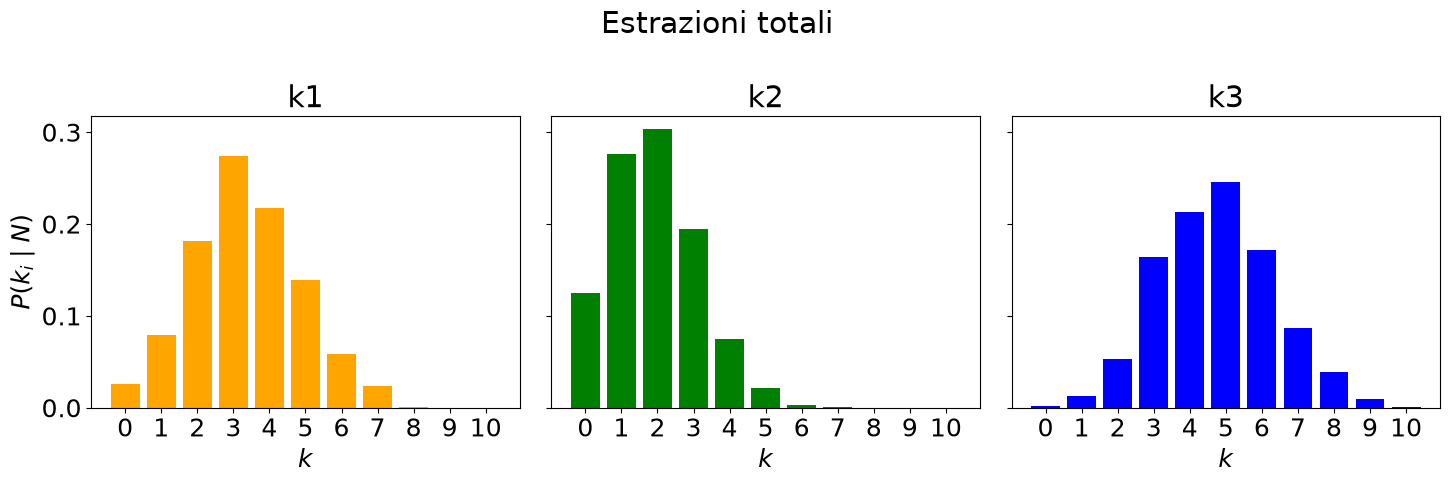

In [256]:
def barplot(ax, mn, label, color):
    k = np.arange(n+1)
    ax.bar(k, mn, color=color)
    ax.set_title(label)
    ax.set_xlabel(r'$k$')
    ax.set_xticks(k)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, mn, label, color in zip(axes, multinom_exp, ['k1', 'k2', 'k3'],['orange','green','blue']):
    barplot(ax, mn, label, color)

axes[0].set_ylabel(r'$P(k_i \mid N)$')
fig.suptitle('Estrazioni totali')
fig.tight_layout()

### Valori di aspettazione
$\langle k_j \rangle = N P_j$

$\langle k_i k_j \rangle = N(N-1) P_i P_j$

$\langle k_i^2 \rangle = N^2 P_i^2-NP_i^2 + NP_i$

In [267]:
def kikj(pi,pj):
    return n*(n-1)*pi*pj

# Frequenza
print('Freq.\tf1\tf2\tf3')
for i in range(n+1):
    print(f'{i}\t{mn1[i]}\t{mn2[i]}\t{mn3[i]}')

# media (da pesare sull'asse delle estrazioni k)
multinom_exp = [mn/NR for mn in [mn1,mn2,mn3]]
#mu_exp = [np.average(np.arange(n+1),weights=mn) for mn in multinom_exp]
#mu2_exp = [np.average((np.arange(n+1))**2,weights=mn) for mn in multinom_exp]

mu_exp = [np.mean(results[:,i]) for i in range(3)]
mu2_exp = [np.mean(results[:,i]**2) for i in range(3)]

mu12_exp = np.mean(results[:,0])*np.mean(results[:,1])
mu13_exp = np.mean(results[:,0])*np.mean(results[:,2])
mu23_exp = np.mean(results[:,1])*np.mean(results[:,2])

mu_th = [n*p for p in p]
mu2_th = [n**2 *p**2 -n*p**2 + n*p for p in p]
# il valore di aspettazione per ogni k_1,2,3 va come E_i = n p_i
p_exp = [mu/n for mu in mu_exp]
print('\n==================')
print(f'<k_i>\tk1\tk2\tk3')
print(f'theory\t{mu_th[0]:.3f}\t{mu_th[1]:.3f}\t{mu_th[2]:.3f}')
print(f'exp\t{mu_exp[0]:.3f}\t{mu_exp[1]:.3f}\t{mu_exp[2]:.3f}')
print('\n==================')
print(f'<(k_i)^2>\tk1\tk2\tk3')
print(f'theory\t\t{mu2_th[0]:.3f}\t{mu2_th[1]:.3f}\t{mu2_th[2]:.3f}')
print(f'exp\t\t{mu2_exp[0]:.3f}\t{mu2_exp[1]:.3f}\t{mu2_exp[2]:.3f}')
print('\n==================')
print(f'<k_i k_j>\tk1,k2\tk2,k3\tk1,k3')
print(f'theory\t\t{kikj(p1,p2):.2f}\t{kikj(p2,p3):.2f}\t{kikj(p1,p3):.2f}')
print(f'exp\t\t{mu12_exp:.2f}\t{mu23_exp:.2f}\t{mu13_exp:.2f}')

Freq.	f1	f2	f3
0	21	119	1
1	86	298	17
2	205	297	44
3	289	186	125
4	217	73	217
5	119	23	239
6	42	4	203
7	16	0	114
8	5	0	32
9	0	0	6
10	0	0	2

<k_i>	k1	k2	k3
theory	3.300	1.900	4.800
exp	3.230	1.881	4.889

<(k_i)^2>	k1	k2	k3
theory		13.101	5.149	25.536
exp		12.570	5.047	26.393

<k_i k_j>	k1,k2	k2,k3	k1,k3
theory		5.64	8.21	14.26
exp		6.08	9.20	15.79


In [268]:
# Matrice di covarianza
cov_exp = np.cov(results, rowvar=False, bias=True)

p_array = np.array(p)
cov_th = -n * np.outer(p_array, p_array)
np.fill_diagonal(cov_th, n * p_array * (1 - p_array))

np.set_printoptions(precision=3, suppress=True)
print('Covariance matrix - theory')
print(cov_th)
print('\nCovariance matrix - experiment')
print(cov_exp)

Covariance matrix - theory
[[ 2.211 -0.627 -1.584]
 [-0.627  1.539 -0.912]
 [-1.584 -0.912  2.496]]

Covariance matrix - experiment
[[ 2.137 -0.578 -1.559]
 [-0.578  1.509 -0.931]
 [-1.559 -0.931  2.491]]


In [ ]:
# matrice di covarianza


In [261]:
# confronto con realizzazioni sperimentali delle triplette

def lookup_result(results,k1,k2,k3):

  if k1+k2+k3 != n:
    raise ValueError('Error in evaluation: k1+k2+k3 =/= n')
  
  counter = 0
  for j in range(results.shape[0]): # loop sulle righe
    if results[j,0] == k1 and results[j,1] == k2 and results[j,2] == k3:
      counter += 1

  return counter/results.shape[0]

def lookup_theory(multinomial,k1,k2,k3):
  return multinomial.pmf([k1,k2,k3])


triplets=[[1,3,6],[4,3,3],[8,1,1],[2,5,3],[6,2,2]]
print('Triplet\t\tTheory\tExp')
for t in triplets:
  print(f'{t}\t{lookup_theory(multinom,t[0],t[1],t[2]):.3f}\t{lookup_result(results,t[0],t[1],t[2]):.3f}')

Triplet		Theory	Exp
[1, 3, 6]	0.023	0.016
[4, 3, 3]	0.038	0.034
[8, 1, 1]	0.001	0.003
[2, 5, 3]	0.008	0.008
[6, 2, 2]	0.014	0.013
